In [13]:
import os
import numpy as np
os.environ["KERAS_BACKEND"] = "jax"
import keras
from keras import layers
from datasets import load_dataset


In [14]:
dataset = load_dataset("zalando-datasets/fashion_mnist")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


In [ ]:

print(dataset["train"]["label"])
# print(dataset["train"].features)
# print(dataset["train"][0])
x = np.array(dataset["train"]["label"])
print(x.shape)
print(x.dtype)
print(x.min())
print(x.max())

In [ ]:

print(dataset["train"]["image"])
# print(dataset["train"].features)
# print(dataset["train"][0])
x = np.array(dataset["train"]["image"])
print(x.shape)
print(x.dtype)
print(x.min())
print(x.max())

Formattazione dei samples

In [15]:
# Creo un tensore train_image con le immagini del dataset
# ne modifico la forma, avendo 60000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

x = np.array(dataset["train"]["image"])

train_images = x.reshape((60000, 28 * 28))
train_images= train_images.astype("float32")
train_images /= 255.0

train_labels = np.array(dataset["train"]["label"])

print("------TRAINING SAMPLES-------")
print(train_images.shape)
print(train_images.dtype)
print(train_images.min())
print(train_images.max())

print("------TRAINING LABELS-------")
print(train_labels.shape)
print(train_labels.dtype)
print(train_labels.min())
print(train_labels.max())


# Creo un tensore tratest_images con le immagini del dataset
# ne modifico la forma, avendo 10000 immagini da 28*28 pixel
# ogni pixel può assumere valori da 0 (nero) a 255 (bianco)
# da 0 a 255 sono sfumature di grigio

y = np.array(dataset["test"]["image"])

test_images = y.reshape((10000, 28 * 28))
test_images= test_images.astype("float32")
test_images /= 255.0

test_labels = np.array(dataset["test"]["label"])

print("------TEST SAMPLES-------")
print(test_images.shape)
print(test_images.dtype)
print(test_images.min())
print(test_images.max())

print("------TEST LABELS-------")
print(test_labels.shape)
print(test_labels.dtype)
print(test_labels.min())
print(test_labels.max())


------TRAINING SAMPLES-------
(60000, 784)
float32
0.0
1.0
------TRAINING LABELS-------
(60000,)
int64
0
9
------TEST SAMPLES-------
(10000, 784)
float32
0.0
1.0
------TEST LABELS-------
(10000,)
int64
0
9


-----------MODEL SUMMARY-----------


Model: "Fashion_MNIST_model_mini"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Uno (Dense)                     │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

-----------MODEL LAYERS-------------
0 Input_layer InputLayer
1 Uno Dense
2 dense_4 Dense
3 dense_5 Dense
Epoch 1/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8026 - loss: 0.5662 - val_accuracy: 0.8470 - val_loss: 0.4406
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8566 - loss: 0.3993 - val_accuracy: 0.8579 - val_loss: 0.4014
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8703 - loss: 0.3583 - val_accuracy: 0.8662 - val_loss: 0.3737
Epoch 4/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8791 - loss: 0.3314 - val_accuracy: 0.8677 - val_loss: 0.3596
Epoch 5/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8865 - loss: 0.3107 - val_accuracy: 0.8718 - val_loss: 0.3520
Epoch 6/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8922 - loss: 0.2927 - val_accuracy: 0.8702 - val_loss: 0.3543
Epoch 7/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8974 - loss: 0.2777 - val_accuracy: 0.8742 - val_loss: 0.340

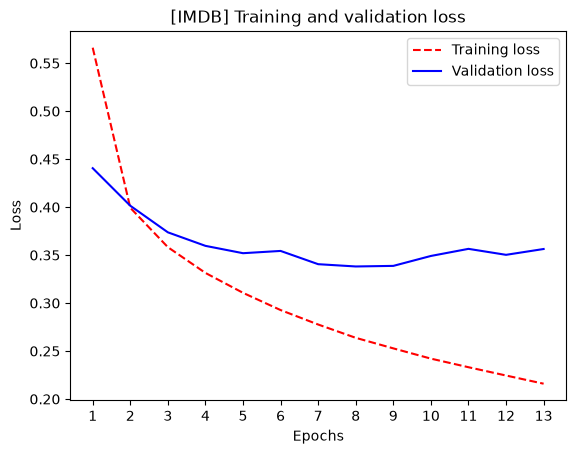

In [16]:
keras.utils.set_random_seed(42)

inputs = keras.Input(shape=(28*28,), name = "Input_layer")
features_1 = layers.Dense(128, activation="relu", name="Uno")(inputs)
features_2 = layers.Dense(64, activation="relu")(features_1)
output = layers.Dense(10, activation="softmax")(features_2)


model = keras.Model(
    inputs = inputs,
    outputs = output,
    name = "Fashion_MNIST_model_mini"
)

print("-----------MODEL SUMMARY-----------")
model.summary()

print("-----------MODEL LAYERS-------------")
for i, layer in enumerate(model.layers):
    print(i, layer.name, layer.__class__.__name__)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience=5,
    restore_best_weights=True
)

tensorboard = keras.callbacks.TensorBoard(
    log_dir = "logs"
)


history = model.fit(
    train_images,
    train_labels,
    epochs=20,
    batch_size=125,
    validation_split=0.2,
    callbacks = [early_stopping, tensorboard]
    )


import matplotlib.pyplot as plt

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "r--", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("[IMDB] Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

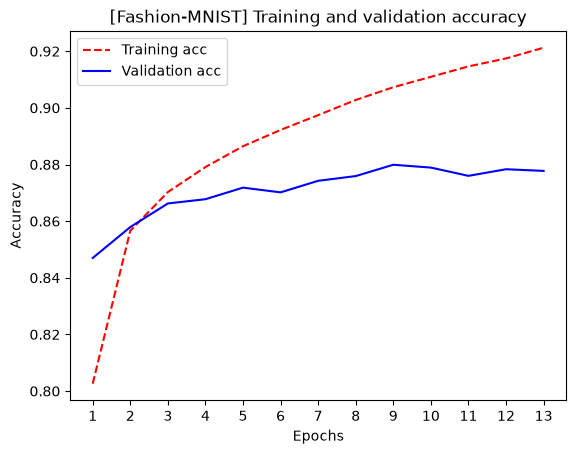

In [17]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("[Fashion-MNIST] Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [18]:
print(f"Ultima training accuracy: "
      f"{history.history['accuracy'][-1]:.2%}")

print(f"Ultima validation accuracy: "
      f"{history.history['val_accuracy'][-1]:.2%}")

print(f"Migliore validation accuracy: "
      f"{max(history.history['val_accuracy']):.2%}")

Ultima training accuracy: 92.12%
Ultima validation accuracy: 87.77%
Migliore validation accuracy: 87.99%


In [19]:
import numpy as np

best_epoch = np.argmin(history.history["val_loss"])

print(f"Epoca migliore: {best_epoch + 1}")
print(
    "Validation loss minima:",
    history.history["val_loss"][best_epoch]
)
print(
    "Validation accuracy in quell'epoca:",
    f"{history.history['val_accuracy'][best_epoch]:.2%}"
)

Epoca migliore: 8
Validation loss minima: 0.3381538987159729
Validation accuracy in quell'epoca: 87.59%
